# Contrails Flight Matching Library Demo (`SingleFrameContrailMatcher`)

This notebook demonstrates how to use `SingleFrameContrailMatcher.match_score` and `advect_flight_to_time` from the open-sourced flight matching library (`matching_lib`):

1. Create a synthetic `pycontrails.Flight` trajectory.
2. Create a synthetic 4D weather dataset (`u`, `v`, `w`, `t`).
3. Advect all flight waypoints to a single satellite observation timestamp (specifically the observed contrail's detection time) using `matching_lib.advect_flight_to_time`.
4. Convert a GeoJSON contrail detection to a `LinearContrail` via `matching_lib.convert_geojson` and score it against the advected flight using `SingleFrameContrailMatcher.match_score`.
5. Visualize the original flight path, the advected flight path, the GOES-East parallax-corrected flight path, and the detected contrail.

In [17]:
%load_ext autoreload
%autoreload 2

import os
import sys

# Point sys.path to the repository root (the parent of the notebooks directory)
# so that the 'src' directory is treated as a top-level package.
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# If '../src' was added to sys.path in a previous execution, remove it to avoid collisions
src_path = os.path.abspath(os.path.join(os.getcwd(), '../src'))
if src_path in sys.path:
    sys.path.remove(src_path)

import geojson
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pycontrails import Flight
import xarray as xr
import advection.utils.casting as casting
from src.flight_matching import single_frame_matching as matching_lib
from src.flight_matching.utils import projection


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Create a Synthetic Flight

We define a synthetic flight segment with 10 waypoints spaced 5 minutes apart between `12:00 UTC` and `12:45 UTC` on `2023-01-01`, flying northeastward across the central US at ~10,668 m / ~238 hPa.

> **Important Input Assumption (Waypoint Count & Sampling Rate):** To maximize JAX JIT cache hits during optimization, `matching_lib` pads each flight's waypoints at a given observation timestamp to a fixed length of `matching_lib.JIT_PADDED_LENGTH = 150` parcels (sized for a typical ~2-hour advection window at a 1-minute flight sampling rate, or ~120 parcels). If a flight contains more than 150 waypoints at a single timestamp, it is not truncated, but `matching_lib` will emit a warning and miss the JAX JIT cache, which can make matching significantly slower if many flights exceed this length.

In [18]:
num_waypoints = 10
waypoint_times = np.datetime64('2023-01-01T12:00:00', 'ns') + (
    np.arange(num_waypoints) * np.timedelta64(5, 'm')
)

fl = Flight(
    data={
        'time': waypoint_times,
        'latitude': np.linspace(40.0, 41.8, num_waypoints),
        'longitude': np.linspace(-100.0, -96.4, num_waypoints),
        'altitude': np.full(num_waypoints, 10668.0),  # ~35,000 ft in meters
    },
    flight_id='demo_flight_001',
)

time_hours = casting.timetype_to_float(
    fl.data['time'], unit=casting.Units.HOURS
)

print(f'Created Flight {fl.attrs["flight_id"]!r} with {len(fl)} waypoints.')
print(f'Waypoint time range: {waypoint_times[0]} to {waypoint_times[-1]}')

Created Flight 'demo_flight_001' with 10 waypoints.
Waypoint time range: 2023-01-01T12:00:00.000000000 to 2023-01-01T12:45:00.000000000


## 2. Generate Synthetic Weather Data

We construct a synthetic `xarray.Dataset` containing 4D wind velocities `u` (eastward, m/s), `v` (northward, m/s), `w` (vertical, Pa/s), and temperature `t` (K) spanning the region and time window of the flight and its subsequent advection.

In [19]:
rng = np.random.default_rng(42)

lats = np.linspace(38.0, 45.0, 15)
lons = np.linspace(-102.0, -90.0, 25)
levels = np.array([200.0, 250.0, 300.0])
times = np.arange(time_hours.min() - 1.0, time_hours.max() + 3.0, 0.5)
grid_shape = (len(times), len(levels), len(lats), len(lons))

# Predominantly eastward + slightly southward wind with mild spatial shear
u_wind = (
    35.0
    + 0.2 * (levels - 250.0).reshape(1, -1, 1, 1)
    + 2.0 * np.sin(np.deg2rad(lats * 20.0)).reshape(1, 1, -1, 1)
    + rng.normal(scale=0.5, size=grid_shape)
)
v_wind = (
    -15.0
    - 0.1 * (lons + 98.0).reshape(1, 1, 1, -1)
    + rng.normal(scale=0.5, size=grid_shape)
)
w_wind = rng.normal(scale=0.01, size=grid_shape)
t_temp = (
    220.0
    + 0.1 * (levels - 250.0).reshape(1, -1, 1, 1)
    - 0.4 * (lats - 41.0).reshape(1, 1, -1, 1)
    + rng.normal(scale=0.1, size=grid_shape)
)

weather_ds = xr.Dataset(
    {
        'u': (['time', 'level', 'latitude', 'longitude'], u_wind),
        'v': (['time', 'level', 'latitude', 'longitude'], v_wind),
        'w': (['time', 'level', 'latitude', 'longitude'], w_wind),
        't': (['time', 'level', 'latitude', 'longitude'], t_temp),
    },
    coords={
        'time': times,
        'level': levels,
        'latitude': lats,
        'longitude': lons,
    },
)

print(
    f'Weather grid: lat [{lats.min()}, {lats.max()}], '
    f'lon [{lons.min()}, {lons.max()}], '
    f'time [{times.min()}h, {times.max()}h]'
)

Weather grid: lat [38.0, 45.0], lon [-102.0, -90.0], time [464603.0h, 464607.5h]


## 3. Advect All Flight Waypoints to a Single Observation Time

Contrails from Google's GetDetections endpoint are detected in a single satellite frame (which we define here in `target_time` at `2023-01-01 13:30:00 UTC`). As such, for any given flight, waypoints recorded before the `target_time` must be advected to that **same target timestamp**, rather than advecting every waypoint forward by a uniform duration.

For example, given the sample flight in the previous cell, which is advected to 13:30 UTC:
* The first waypoint (emitted at `12:00 UTC`) is advected **1.50 hours** forward.
* The last waypoint (emitted at `12:45 UTC`) is advected **0.75 hours** forward.

We use `matching_lib.advect_flight_to_time(fl, target_time, weather_ds)` to advect the flight's waypoints to `target_time`. Note that a **flight must be advected** in order to invoke `SingleFrameContrailMatcher.match_score()`, and not doing so will raise a `ValueError`.

> **Note on Advection Window & Waypoint Count (`JIT_PADDED_LENGTH = 150`):** When filtering or slicing flight trajectories prior to advection and matching, keep in mind that `matching_lib` pads flight parcels to `matching_lib.JIT_PADDED_LENGTH = 150` (assuming e.g. a 2-hour advection window with 1-minute waypoint sampling). Passing an advected flight with more than 150 parcels at `target_time` will trigger a warning and bypass the fixed-shape JAX JIT cache, degrading matching performance.

In [20]:
target_time = pd.Timestamp('2023-01-01 13:30:00', tz='UTC')

advected_flight = matching_lib.advect_flight_to_time(
    fl, target_time, weather_ds
)

age_hrs = (
    advected_flight.data['advected_time'] - advected_flight.data['time']
) / np.timedelta64(1, 'h')

summary_df = pd.DataFrame({
    'original_time': fl.data['time'],
    'advected_time': advected_flight.data['advected_time'],
    'age_hrs': age_hrs,
    'orig_lat': fl.data['latitude'],
    'orig_lon': fl.data['longitude'],
    'adv_lat': advected_flight.data['latitude'],
    'adv_lon': advected_flight.data['longitude'],
    'adv_alt_m': advected_flight.data['altitude'],
})
display(summary_df)

,original_time,advected_time,age_hrs,orig_lat,orig_lon,adv_lat,adv_lon,adv_alt_m
0,2023-01-01 12:00:00,2023-01-01 13:30:00,1.500000,40.0,-100.0,39.263882,-97.828216,10664.401480
1,2023-01-01 12:05:00,2023-01-01 13:30:00,1.416667,40.2,-99.6,39.517101,-97.543388,10665.565932
2,2023-01-01 12:10:00,2023-01-01 13:30:00,1.333333,40.4,-99.2,39.758614,-97.247423,10665.480965
3,2023-01-01 12:15:00,2023-01-01 13:30:00,1.250000,40.6,-98.8,39.992298,-96.959342,10662.574529
4,2023-01-01 12:20:00,2023-01-01 13:30:00,1.166667,40.8,-98.4,40.231185,-96.675750,10663.032790
5,2023-01-01 12:25:00,2023-01-01 13:30:00,1.083333,41.0,-98.0,40.471165,-96.403277,10664.318351
6,2023-01-01 12:30:00,2023-01-01 13:30:00,1.000000,41.2,-97.6,40.711642,-96.127805,10664.769119
7,2023-01-01 12:35:00,2023-01-01 13:30:00,0.916667,41.4,-97.2,40.947227,-95.836428,10670.533971
8,2023-01-01 12:40:00,2023-01-01 13:30:00,0.833333,41.6,-96.8,41.185906,-95.556726,10667.429059
9,2023-01-01 12:45:00,2023-01-01 13:30:00,0.750000,41.8,-96.4,41.433019,-95.277584,10664.165095


## 4. Convert GeoJSON Contrail Detection & Compute Match Score

Contrail detections from Google's Detections API are returned as GeoJSON `Feature` objects (`LineString`). For more details, see https://developers.google.com/contrails/reference/v2/detections/getDetections.

We convert the GeoJSON `Feature` into a `LinearContrail` via `matching_lib.convert_geojson`, which automatically resolves the satellite longitude from `satellite_origin` (`'GOES-EAST-FULL-DISK'` $\rightarrow -75.0^\circ$).

`SingleFrameContrailMatcher.match_score` then projects the advected flight waypoints into the satellite's perspective frame, applies validation heuristics, and runs optimization in the contrail's $(v, w)$ coordinate frame.

In [21]:
GOES_EAST_LON = -75.0
GOES_EAST_ALT_KM = 35786.023

matcher = matching_lib.SingleFrameContrailMatcher(
    satellite_longitude=GOES_EAST_LON,
    satellite_altitude_km=GOES_EAST_ALT_KM,
)

# Define a candidate contrail in GeoJSON format (matching Google's GetDetections
# API schema) near waypoints 1..7 of the advected flight, and convert it to a
# LinearContrail via matching_lib.convert_geojson.
mean_altitude_m = float(np.mean(advected_flight.data['altitude']))
contrail_geojson = geojson.Feature(
    geometry=geojson.LineString([
        (
            float(advected_flight.data['longitude'][1]),
            float(advected_flight.data['latitude'][1] + 0.05),
            mean_altitude_m,
        ),
        (
            float(advected_flight.data['longitude'][7]),
            float(advected_flight.data['latitude'][7] + 0.01),
            mean_altitude_m,
        ),
    ]),
    properties={
        'time': target_time.isoformat(),
        'satellite_origin': 'GOES-EAST-FULL-DISK',
    },
)
contrail = matching_lib.convert_geojson(contrail_geojson)

# Note: matcher.match_score also accepts contrail_geojson directly (and will
# automatically convert the geojson into a LinearContrail object).
match_result = matcher.match_score(advected_flight, contrail)

if match_result is not None:
  sc = match_result.score_components
  print(f'Converted LinearContrail: {contrail}\n')
  print(f'Matched flight_id:        {match_result.flight_id}')
  print(
      f'Total match score:        {match_result.score:.4f} '
      f'(threshold = {matching_lib.MATCH_SCORE_THRESHOLD})'
  )
  print(
      'Overlapping emission time:'
      f' {pd.Timestamp(match_result.overlap_start_timestamp, unit="s", tz="UTC")}'
      ' ->'
      f' {pd.Timestamp(match_result.overlap_end_timestamp, unit="s", tz="UTC")}'
  )
  print('\nScore Components:')
  print(f'  fit_score:              {sc.fit_score:.4f}')
  print(f'  shift_score:            {sc.shift_score:.4f}')
  print(f'  angle_score:            {sc.angle_score:.4f}')
  print(f'  age_score:              {sc.age_score:.4f}')
  print('\nLearned Alignment Parameters:')
  print(f'  v_offset (along, km):   {sc.v_offset:.4f}')
  print(f'  w_offset (normal, km):  {sc.w_offset:.4f}')
  print(
      f'  theta (rad / deg):      {sc.theta:.4f} rad'
      f' ({np.rad2deg(sc.theta):.2f} deg)'
  )
  print(f'  mean parcel age (hrs):  {sc.age_hrs:.4f}')
else:
  print('No match found. Rejection counters:', matcher.counters)

Converted LinearContrail: LinearContrail(lon1=-97.543388, lat1=39.567101, lon2=-95.836428, lat2=40.957227, timestamp=1672579800, altitude_m=10665.227129, satellite_longitude=-75.0)

Matched flight_id:        demo_flight_001
Total match score:        2.4718 (threshold = 3.0)
Overlapping emission time: 2023-01-01 12:10:00+00:00 -> 2023-01-01 12:30:00+00:00

Score Components:
  fit_score:              0.5510
  shift_score:            0.7244
  angle_score:            0.0297
  age_score:              1.1667

Learned Alignment Parameters:
  v_offset (along, km):   0.1740
  w_offset (normal, km):  -9.9285
  theta (rad / deg):      -0.0175 rad (-1.00 deg)
  mean parcel age (hrs):  1.1667


## 5. Step-by-Step Visualization of Single-Frame Contrail Matching

We visualize each stage of the single-frame flight matching pipeline step by step:
1. **Original Flight Path** (geodetic, `12:00` – `12:45 UTC`)
2. **Original Flight Path + Advection** at `13:30 UTC` (geodetic)
3. **Original Flight Path + Advection + Parallax Correction** at `13:30 UTC` (the geostationary GOES-East-projected view computed inside `match_score`)
4. **Original Flight Path + Advection + Parallax Correction + Detected Contrail** at `13:30 UTC` (full flight matching view)

### 5.1 Original Flight Path

We first plot the original flight path.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


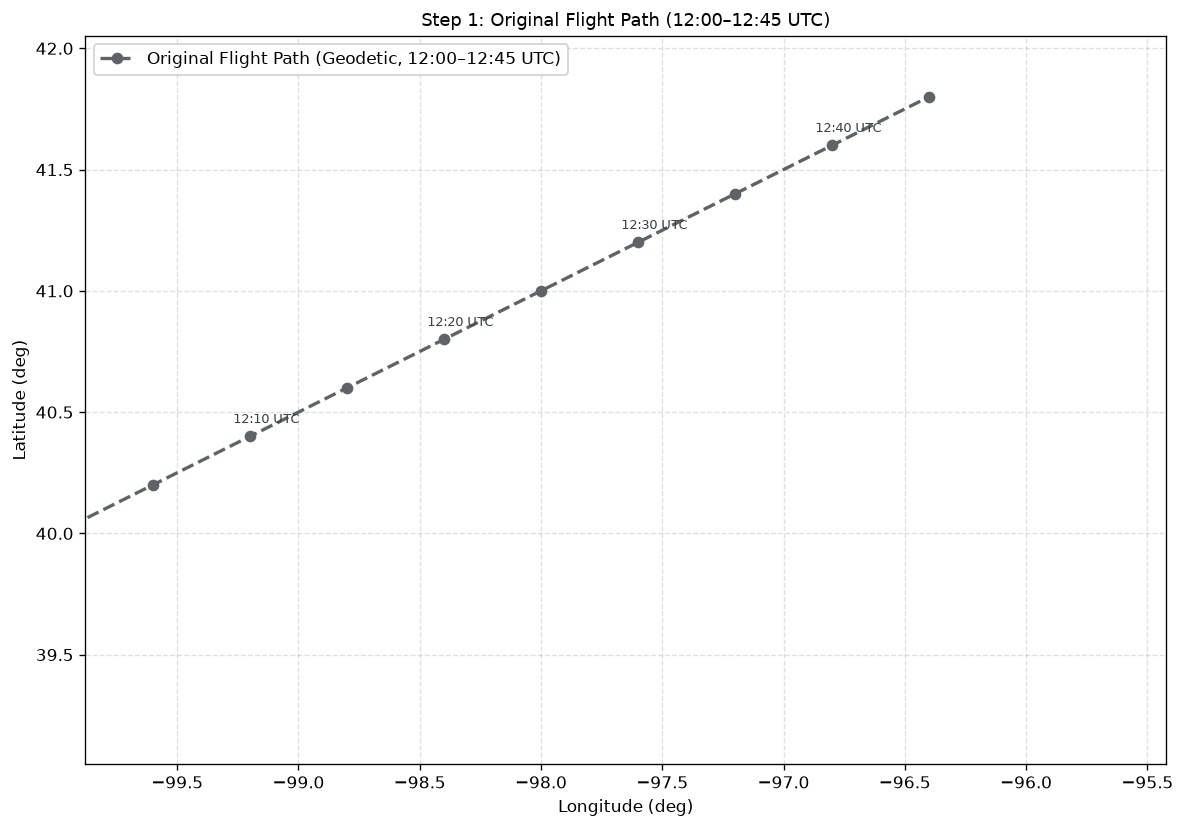

In [22]:
orig_lons = fl.data['longitude']
orig_lats = fl.data['latitude']
time_labels = [pd.Timestamp(t).strftime('%H:%M') for t in fl.data['time']]

# Shared axis bounds so each step can be compared directly.
PLOT_XLIM = (-100.3, -95.0)
PLOT_YLIM = (39.0, 42.1)

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

# 1. Original flight path (geodetic, 12:00 - 12:45 UTC)
ax.plot(
    orig_lons,
    orig_lats,
    color='#5f6368',
    linestyle='--',
    linewidth=2.0,
    marker='o',
    markersize=6,
    label='Original Flight Path (Geodetic, 12:00–12:45 UTC)',
)
for i in range(0, len(time_labels), 2):
  ax.annotate(
      f'{time_labels[i]} UTC',
      (orig_lons[i], orig_lats[i]),
      textcoords='offset points',
      xytext=(-10, 8),
      fontsize=8,
      color='#3c4043',
  )

ax.set_title('Step 1: Original Flight Path (12:00–12:45 UTC)', fontsize=11)
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')
ax.set_xlim(PLOT_XLIM)
ax.set_ylim(PLOT_YLIM)
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

### 5.2 Original Flight Path + Advection
We plot the original flight path, and its advection to the same point in time as our detected contrail.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


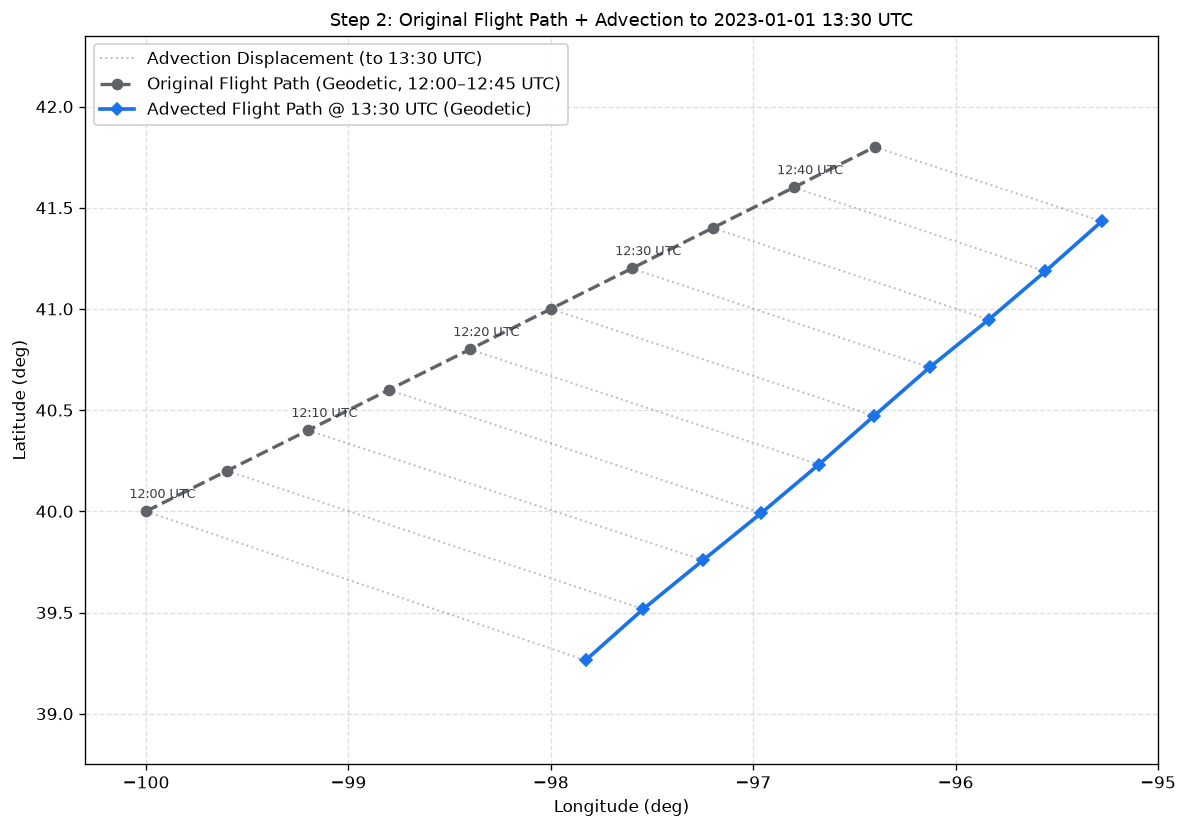

In [23]:
adv_lons = advected_flight.data['longitude']
adv_lats = advected_flight.data['latitude']

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

# Waypoint advection displacement lines (original -> advected at 13:30 UTC)
for i, (lon0, lat0, lon1, lat1) in enumerate(
    zip(orig_lons, orig_lats, adv_lons, adv_lats)
):
  ax.plot(
      [lon0, lon1],
      [lat0, lat1],
      color='gray',
      linestyle=':',
      linewidth=1.2,
      alpha=0.5,
      label='Advection Displacement (to 13:30 UTC)' if i == 0 else None,
  )

# 1. Original flight path (geodetic, 12:00 - 12:45 UTC)
ax.plot(
    orig_lons,
    orig_lats,
    color='#5f6368',
    linestyle='--',
    linewidth=2.0,
    marker='o',
    markersize=6,
    label='Original Flight Path (Geodetic, 12:00–12:45 UTC)',
)
for i in range(0, len(time_labels), 2):
  ax.annotate(
      f'{time_labels[i]} UTC',
      (orig_lons[i], orig_lats[i]),
      textcoords='offset points',
      xytext=(-10, 8),
      fontsize=8,
      color='#3c4043',
  )

# 2. Advected flight path at 13:30 UTC (geodetic)
ax.plot(
    adv_lons,
    adv_lats,
    color='#1a73e8',
    linestyle='-',
    linewidth=2.2,
    marker='D',
    markersize=5,
    label='Advected Flight Path @ 13:30 UTC (Geodetic)',
)

ax.set_title(
    'Step 2: Original Flight Path + Advection to'
    f' {target_time.strftime("%Y-%m-%d %H:%M UTC")}',
    fontsize=11,
)
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')
ax.set_xlim(PLOT_XLIM)
ax.set_ylim(PLOT_YLIM)
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

### 5.3 Original Flight Path + Advection + Parallax Correction
Flight data comes in via geodetic coordinates, but contrails come in via geostationary satellite detection, which means that we need to parallax-correct the flight to match that of the satellite detection. We plot here the original flight path, its advection, and its parallax-corrected advection.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


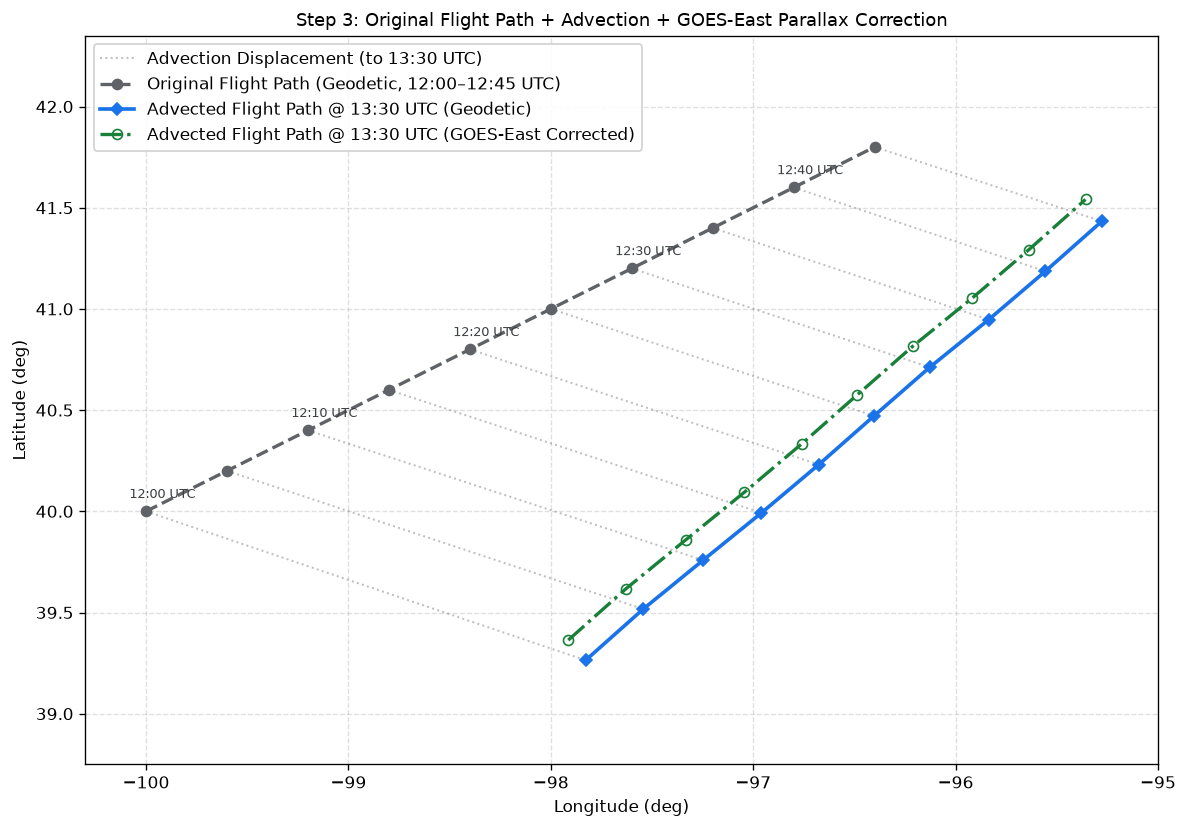

In [24]:
# Note that obs_lats and obs_lons are already calculated as part of the
# match_score function. They are included here for plotting purposes.
obs_lats, obs_lons = projection.geostationary_parallax_correction(
    a_lat_degrees=adv_lats,
    a_lng_degrees=adv_lons,
    a_altitude_km=advected_flight.data['altitude'] / 1000.0,
    b_altitude_km=0.0,
    satellite_longitude=GOES_EAST_LON,
    satellite_altitude_km=GOES_EAST_ALT_KM,
)

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

# Waypoint advection displacement lines (original -> advected at 13:30 UTC)
for i, (lon0, lat0, lon1, lat1) in enumerate(
    zip(orig_lons, orig_lats, adv_lons, adv_lats)
):
  ax.plot(
      [lon0, lon1],
      [lat0, lat1],
      color='gray',
      linestyle=':',
      linewidth=1.2,
      alpha=0.5,
      label='Advection Displacement (to 13:30 UTC)' if i == 0 else None,
  )

# 1. Original flight path (geodetic, 12:00 - 12:45 UTC)
ax.plot(
    orig_lons,
    orig_lats,
    color='#5f6368',
    linestyle='--',
    linewidth=2.0,
    marker='o',
    markersize=6,
    label='Original Flight Path (Geodetic, 12:00–12:45 UTC)',
)
for i in range(0, len(time_labels), 2):
  ax.annotate(
      f'{time_labels[i]} UTC',
      (orig_lons[i], orig_lats[i]),
      textcoords='offset points',
      xytext=(-10, 8),
      fontsize=8,
      color='#3c4043',
  )

# 2. Advected flight path at 13:30 UTC (geodetic)
ax.plot(
    adv_lons,
    adv_lats,
    color='#1a73e8',
    linestyle='-',
    linewidth=2.2,
    marker='D',
    markersize=5,
    label='Advected Flight Path @ 13:30 UTC (Geodetic)',
)

# 3. Advected flight path at 13:30 UTC corrected to GOES-East (done in match_score)
ax.plot(
    obs_lons,
    obs_lats,
    color='#188038',
    linestyle='-.',
    linewidth=2.0,
    marker='o',
    markerfacecolor='none',
    markersize=6,
    label='Advected Flight Path @ 13:30 UTC (GOES-East Corrected)',
)

ax.set_title(
    'Step 3: Original Flight Path + Advection + GOES-East Parallax Correction',
    fontsize=11,
)
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')
ax.set_xlim(PLOT_XLIM)
ax.set_ylim(PLOT_YLIM)
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

### 5.4 Original Flight Path + Advection + Parallax Correction + Detected Contrail

Finally, flight-contrail match scores are calculated between the parallax-corrected, advected flight path (the green dotted line in the below plot) and the detected contrail (the red solid line).

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


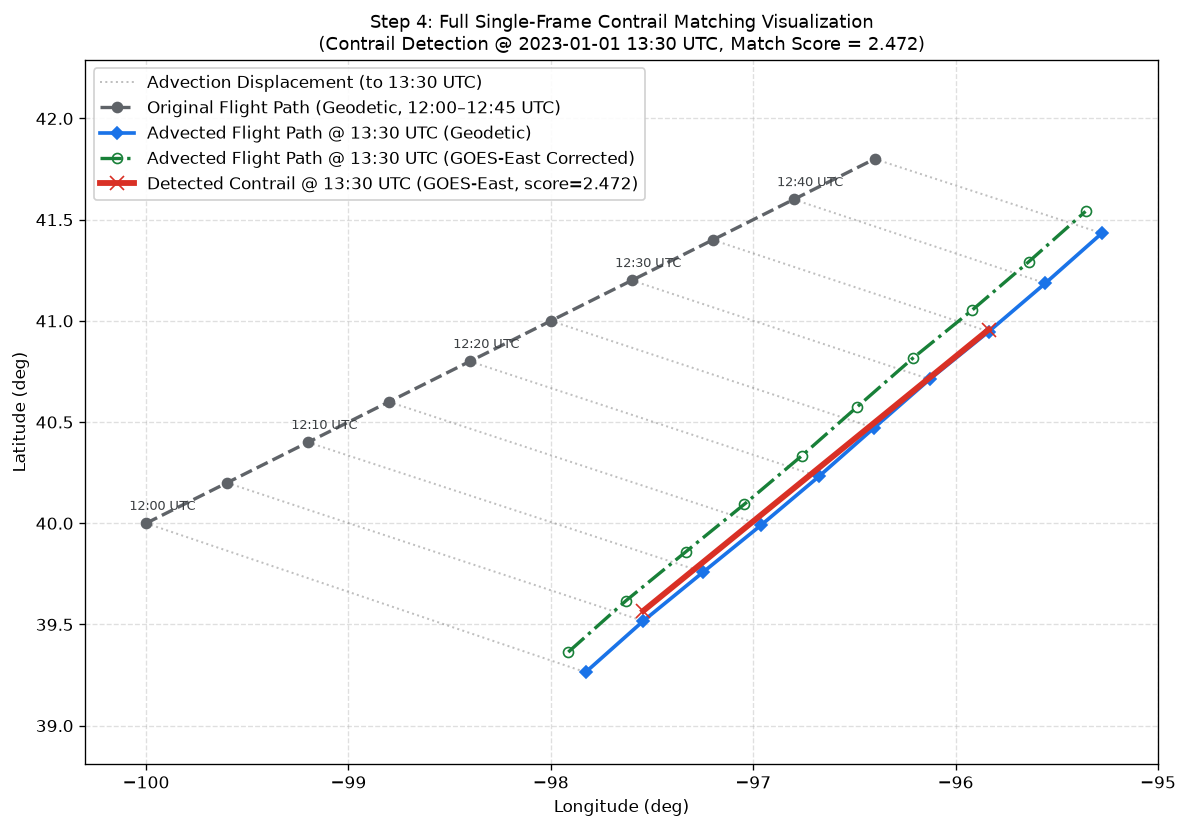

In [25]:
fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

# Waypoint advection displacement lines (original -> advected at 13:30 UTC)
for i, (lon0, lat0, lon1, lat1) in enumerate(
    zip(orig_lons, orig_lats, adv_lons, adv_lats)
):
  ax.plot(
      [lon0, lon1],
      [lat0, lat1],
      color='gray',
      linestyle=':',
      linewidth=1.2,
      alpha=0.5,
      label='Advection Displacement (to 13:30 UTC)' if i == 0 else None,
  )

# 1. Original flight path (geodetic, 12:00 - 12:45 UTC)
ax.plot(
    orig_lons,
    orig_lats,
    color='#5f6368',
    linestyle='--',
    linewidth=2.0,
    marker='o',
    markersize=6,
    label='Original Flight Path (Geodetic, 12:00–12:45 UTC)',
)
for i in range(0, len(time_labels), 2):
  ax.annotate(
      f'{time_labels[i]} UTC',
      (orig_lons[i], orig_lats[i]),
      textcoords='offset points',
      xytext=(-10, 8),
      fontsize=8,
      color='#3c4043',
  )

# 2. Advected flight path at 13:30 UTC (geodetic)
ax.plot(
    adv_lons,
    adv_lats,
    color='#1a73e8',
    linestyle='-',
    linewidth=2.2,
    marker='D',
    markersize=5,
    label='Advected Flight Path @ 13:30 UTC (Geodetic)',
)

# 3. Advected flight path at 13:30 UTC corrected to GOES-East (done in match_score)
ax.plot(
    obs_lons,
    obs_lats,
    color='#188038',
    linestyle='-.',
    linewidth=2.0,
    marker='o',
    markerfacecolor='none',
    markersize=6,
    label='Advected Flight Path @ 13:30 UTC (GOES-East Corrected)',
)

# 4. Detected Linear Contrail at 13:30 UTC (geostationary GOES-East)
score_str = f'{match_result.score:.3f}' if match_result is not None else 'N/A'
ax.plot(
    [contrail.lon1, contrail.lon2],
    [contrail.lat1, contrail.lat2],
    color='#d93025',
    linestyle='-',
    linewidth=3.5,
    marker='x',
    markersize=8,
    label=f'Detected Contrail @ 13:30 UTC (GOES-East, score={score_str})',
)

ax.set_title(
    'Step 4: Full Single-Frame Contrail Matching Visualization\n(Contrail'
    f' Detection @ {target_time.strftime("%Y-%m-%d %H:%M UTC")}, Match Score ='
    f' {score_str})',
    fontsize=11,
)
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')
ax.set_xlim(PLOT_XLIM)
ax.set_ylim(PLOT_YLIM)
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()